# 6.1BOW及自定义分类器

In [5]:
import os, random, operator, sys
from collections import Counter
import random
import collections
import math
import sys

import re
import numpy as np
from tqdm import tqdm
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import pandas as pd

## 一些功能函数
需要阅读这些函数来对实验中用到的数据结构，步骤有一些理解

In [6]:
def dotProduct(d1, d2):
    """
    @param dict d1: a feature vector represented by a mapping from a feature (string) to a weight (float).
    @param dict d2: same as d1
    @return float: the dot product between d1 and d2
    """
    if len(d1) < len(d2):
        return dotProduct(d2, d1)
    else:
        return sum(d1.get(f, 0) * v for f, v in d2.items())


In [7]:
def increment(d1, scale, d2):
    """
    Implements d1 += scale * d2 for sparse vectors.
    @param dict d1: the feature vector which is mutated.
    @param float scale
    @param dict d2: a feature vector.
    """
    for f, v in d2.items():
        d1[f] = d1.get(f, 0) + v * scale


In [8]:
def pre_data(x):
    '''
    处理“ISO 8859-1” 的控制字符（0x80-0x9F）和文字符号（0xA0-0xFF）。
    '''
    x = re.sub(r'[\u00BD]+', r'one half', x)    #  换为one half

    x = re.sub(r'[\u00C8-\u00CB]+', r'E', x)    #  换为E
    x = re.sub(r'[\u00D9-\u00DC]+', r'U', x)    #  换为U

    x = re.sub(r'[\u00E0-\u00E5]+', r'a', x)    #  换为a
    x = re.sub(r'[\u00E6]+', r'ae', x)          #  换为ae
    x = re.sub(r'[\u00E7]+', r'c', x)           #  换为e
    x = re.sub(r'[\u00E8-\u00EB]+', r'e', x)    #  换为e
    x = re.sub(r'[\u00EC-\u00EF]+', r'i', x)    #  换为i
    x = re.sub(r'[\u00F0]+', r'eth', x)         #  换为eth
    x = re.sub(r'[\u00F1]+', r'n', x)           #  换为n
    x = re.sub(r'[\u00F2-\u00F6]+', r'o', x)    #  换为o
    x = re.sub(r'[\u00F9-\u00FC]+', r'u', x)    #  换为u
    x = re.sub(r"[\u0080-\u009F]+", r" ", x)    #  去除控制字符
    # x = re.sub(r"[^\u0080-\u009F\u00A0-\u00FF]+", r" ", x)  # ^\u0080-\u009F\u00A0-\u00FF
    return x.strip()


In [9]:
def readExamples(path):
    '''
    读取数据
    '''
    examples = []
    for line in open(path, encoding = "ISO-8859-1"):
        # Format of each line: <output label (+1 or -1)> <input sentence>
        y, x = line.split(' ', 1)
        examples.append((pre_data(x), int(y)))
    print('Read %d examples from %s' % (len(examples), path))
    return examples


In [10]:
def evaluatePredictor(examples, predictor):
    '''
    在|examples|上测试|predictor|的性能，返回错误率
    '''
    error = 0
    for x, y in examples:
        if predictor(x) != y:
            error += 1
    return 1.0 * error / len(examples)

## Feature extrator (Your codes here)

### (1) 使用BOW作为特征
(a) 复习BOW
(b) 如何把一个句子（字符串）转化成BOW的特征？

In [11]:
def extractFeatures(x):
    """
    从字符串x中提取特征
    @param string x: 
    @return vector: feature vector representation of x.
    """
    # 将文本拆分为单词并计算其频率
    words = x.split()
    word_counts = collections.Counter(words)
    
    # 忽略频率，构造特征向量（one-hot）
    feature_vector = {}
    for word, _ in word_counts.items():
        feature_vector[word] = 1
    
    return feature_vector

### (4) Test your feature extractor
实现了特征提取函数之后，可以简单地测试输出的正确性

In [12]:
extractFeatures("a truly wonderful wonderful wonderfultale combined with stunning animation .")

{'a': 1,
 'truly': 1,
 'wonderful': 1,
 'wonderfultale': 1,
 'combined': 1,
 'with': 1,
 'stunning': 1,
 'animation': 1,
 '.': 1}

## 学习与梯度更新
你需要理解题目中的loss_function, 自行推导出weights的更新公式，
通过对训练集上样本的迭代，来更新weights

In [13]:

def learnPredictor(trainExamples, validateExamples, featureExtractor, epochs, eta, use_momentum, momentum=0.9):
    '''
    给定训练数据和测试数据，特征提取器|featureExtractor|、训练轮数|numIters|和学习率|eta|，
    返回学习后的权重weights
    你需要实现随机梯度下降优化权重
    '''
    # 返回每次迭代的权重、Loss、训练集和验证集的错误率
    weights, weight_epochs = {}, []
    losses_train, losses_val = [], []
    errors_train, errors_val =  [], []
    #动量
    velocity = {}
    
    for  i in range(0, epochs):        
        with tqdm(total=len(trainExamples), desc=f"[Epoch {(i+1):3d}/{epochs}]") as pbar:
            #本次迭代的Loss
            loss_batch = []
            for j,(x,y) in enumerate(trainExamples):
                # 每10次迭代下降一半的学习率
                if i > 0 and i % 10 == 0:
                    eta *=0.5
                # 提取特征
                features = featureExtractor(x)
                # 计算预测值
                pred = dotProduct(features, weights)
                # 计算梯度
                margin = y * pred
                if margin < 1: 
                    if use_momentum:
                        for f, v in velocity.items():
                            velocity[f] = velocity.get(f, 0) * momentum
                        increment(velocity, eta * y, features)   
                        increment(weights, 1, velocity)   
                    else:
                        increment(weights, eta * y, features)
                       
                # 计算训练损失函数
                loss = max(0, 1 - margin)
                loss_batch.append(loss)

                # 打印loss
                if j > 0 and j % 100 == 0:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(100)
                elif j == len(trainExamples)-1:
                    pbar.set_postfix({'Train Loss': '{:4f}'.format(np.mean(loss_batch))})
                    pbar.update(j % 100+1)
                    
            # 计算验证集损失函数
            valLoss = sum(max(0, 1 - y * dotProduct(featureExtractor(x), weights)) for x, y in validateExamples)/len(validateExamples)
            
            # 计算训练集和验证集的错误率
            trainError = evaluatePredictor(trainExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
            valError= evaluatePredictor(validateExamples, lambda x : (1 if dotProduct(featureExtractor(x), weights) >= 0 else -1))
            loss_batch = np.mean(loss_batch)
            pbar.set_postfix({'Loss(train|val)': '{:4f}|{:4f}'.format(loss_batch, valLoss), 
                              'Error rate(train|val)': '{:4f}|{:4f}'.format(trainError,valError)})

            #记录每次迭代后的Loss、权重和错误率
            weight_epochs.append(weights)
            losses_train.append(loss_batch)
            losses_val.append(valLoss)
            errors_train.append(trainError)
            errors_val.append(valError)
    return weight_epochs, losses_train, losses_val, errors_train, errors_val


## 已经定义好的训练测试流程

### 训练模型

(a) 超参请自行更改 
(b) 自行增加代码来进行训练loss和测试loss变化图的绘制 
(b) 分析性能,模型泛化能力, 权重weights的可解释性等等 

In [14]:
trainExamples = readExamples('data/data_rt.train')
testExamples = readExamples('data/data_rt.test')

# 从源训练集和测试集中各取10%，组合当验证集
trainExamples, validateExamples = train_test_split(trainExamples, test_size=0.1, random_state=10)
testExamples, validateExamples1 = train_test_split(testExamples, test_size=0.1, random_state=10)
validateExamples.extend(validateExamples1)
# 打印训练集、验证集和测试集的样本大小
print('Dataset Size(training|validation|test)={}|{}|{}'.format(len(trainExamples), len(validateExamples), len(testExamples)))

featureExtractor = extractFeatures

Read 3554 examples from data/data_rt.train
Read 3554 examples from data/data_rt.test
Dataset Size(training|validation|test)=3198|712|3198


In [15]:
# 记录调参结果
exec_result = pd.DataFrame(columns=['model', 'epochs', 'eta', 'use_momentum', 'momentum',
                                    'best_epoch', 'best_errors_val', 'best_weights', 
                                    'losses_train', 'losses_val', 'errors_train', 'errors_val'])
# 网格搜索

epochs = 20
for eta in [0.1, 0.05, 0.01, 0.005, 0.001, 0.0005, 0.0001]:
    for use_momentum in [True, False]:
        if use_momentum:
            for momentum in [0.1, 0.5, 0.9]:
                weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                    epochs=epochs, 
                                                                    eta=eta, 
                                                                    use_momentum=use_momentum, 
                                                                    momentum=momentum)  
                best_errors_val = min(errors_val) 
                print('eat={} use_momentum={} momentum={} errors_val={:4f}'.format(eta, use_momentum, momentum, best_errors_val),'\n') 
                best_epoch = errors_val.index(best_errors_val)
                best_weights = weight_epochs[best_epoch]
                exec_result.loc[exec_result.shape[0]] = ['bow', 20, eta, use_momentum, momentum, 
                                                         best_epoch, best_errors_val, best_weights,
                                                         losses_train, losses_val, errors_train, errors_val]    
        else:
            weight_epochs, losses_train, losses_val, errors_train, errors_val = learnPredictor(trainExamples, validateExamples, featureExtractor, 
                                                                    epochs=epochs, 
                                                                    eta=eta, 
                                                                    use_momentum=use_momentum, 
                                                                    momentum=0)    
            print('eat={} use_momentum={} errors_val={:4f}'.format(eta, use_momentum, min(errors_val)),'\n')   
            best_errors_val = min(errors_val) 
            best_epoch = errors_val.index(best_errors_val)
            weights = weight_epochs[best_epoch]
            exec_result.loc[exec_result.shape[0]] = ['bow', 20, eta, use_momentum, 0,
                                                    best_epoch, best_errors_val, best_weights,
                                                    losses_train, losses_val, errors_train, errors_val]   
exec_result.to_csv('./output/exec_result_bow.csv', index=0)


[Epoch  20/20]: 100%|██████████| 3198/3198 [00:00<00:00, 7252.98it/s, Loss(train|val)=0.019040|0.709894, Error rate(train|val)=0.001876|0.287921]


eat=0.1 use_momentum=True momentum=0.1 errors_val=0.278090 



[Epoch  20/20]: 100%|██████████| 3198/3198 [00:00<00:00, 12089.73it/s, Loss(train|val)=0.015499|0.845901, Error rate(train|val)=0.004065|0.285112]


eat=0.1 use_momentum=True momentum=0.5 errors_val=0.280899 



[Epoch  20/20]: 100%|██████████| 3198/3198 [00:00<00:00, 3669.88it/s, Loss(train|val)=0.424644|3.528097, Error rate(train|val)=0.110069|0.372191]


...

eat=0.0001 use_momentum=True momentum=0.5 errors_val=0.410112 



[Epoch  20/20]: 100%|██████████| 3198/3198 [00:08<00:00, 387.69it/s, Loss(train|val)=0.698281|0.788927, Error rate(train|val)=0.276110|0.337079]


eat=0.0001 use_momentum=True momentum=0.9 errors_val=0.334270 



[Epoch  20/20]: 100%|██████████| 3198/3198 [00:00<00:00, 38541.44it/s, Loss(train|val)=0.951283|0.961330, Error rate(train|val)=0.376798|0.410112]


eat=0.0001 use_momentum=False errors_val=0.410112 



### 结果整理

In [16]:
# exec_result.sort_values(by=['best_errors_val'])[['model', 'epochs', 'eta', 'use_momentum', 'momentum', 'best_epoch' ,'best_errors_val']]
exec_result[['model', 'epochs', 'eta', 'use_momentum', 'momentum', 'best_epoch' ,'best_errors_val']]

,model,epochs,eta,use_momentum,momentum,best_epoch,best_errors_val
0,bow,20,0.1000,True,0.1,7,0.278090
1,bow,20,0.1000,True,0.5,8,0.280899
2,bow,20,0.1000,True,0.9,9,0.292135
3,bow,20,0.1000,False,0.0,8,0.280899
4,bow,20,0.0500,True,0.1,6,0.285112
5,bow,20,0.0500,True,0.5,9,0.269663
6,bow,20,0.0500,True,0.9,5,0.283708
7,bow,20,0.0500,False,0.0,6,0.285112
8,bow,20,0.0100,True,0.1,8,0.265449
9,bow,20,0.0100,True,0.5,7,0.272472


#### epoch对结果的影响

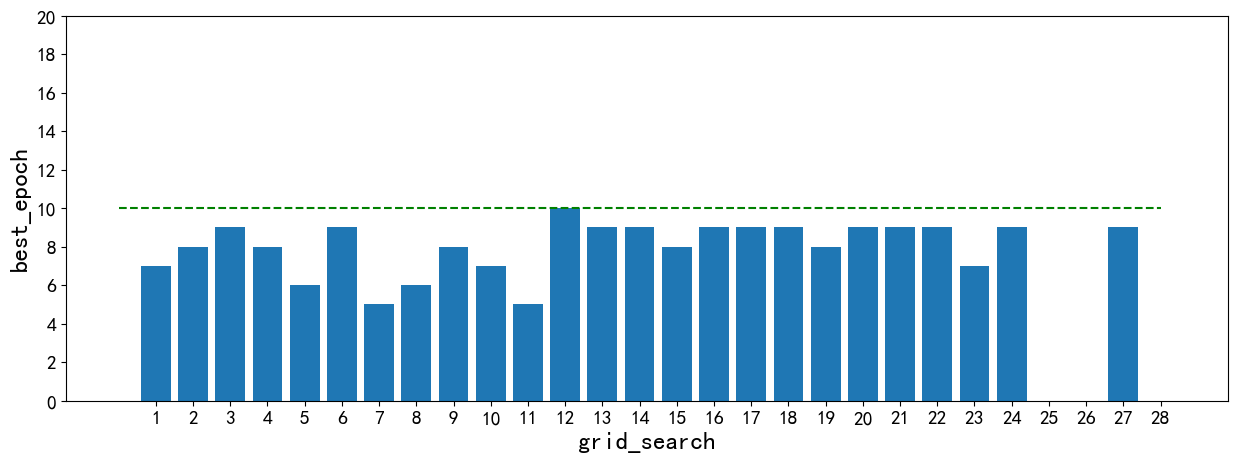

In [17]:
plt.figure(figsize=(15,5), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.bar(list(range(1,len(exec_result)+1)), exec_result['best_epoch'].values.tolist())
plt.plot([0,28],[10,10],c='g',ls='--')
plt.xlabel('grid_search', fontsize=18, fontweight='bold')
plt.ylabel('best_epoch', fontsize=18, fontweight='bold')
plt.xticks(range(1,len(exec_result)+1), fontsize=14)
plt.yticks(range(0,21,2),fontsize=14)
plt.show()

#### 动量对结果的影响

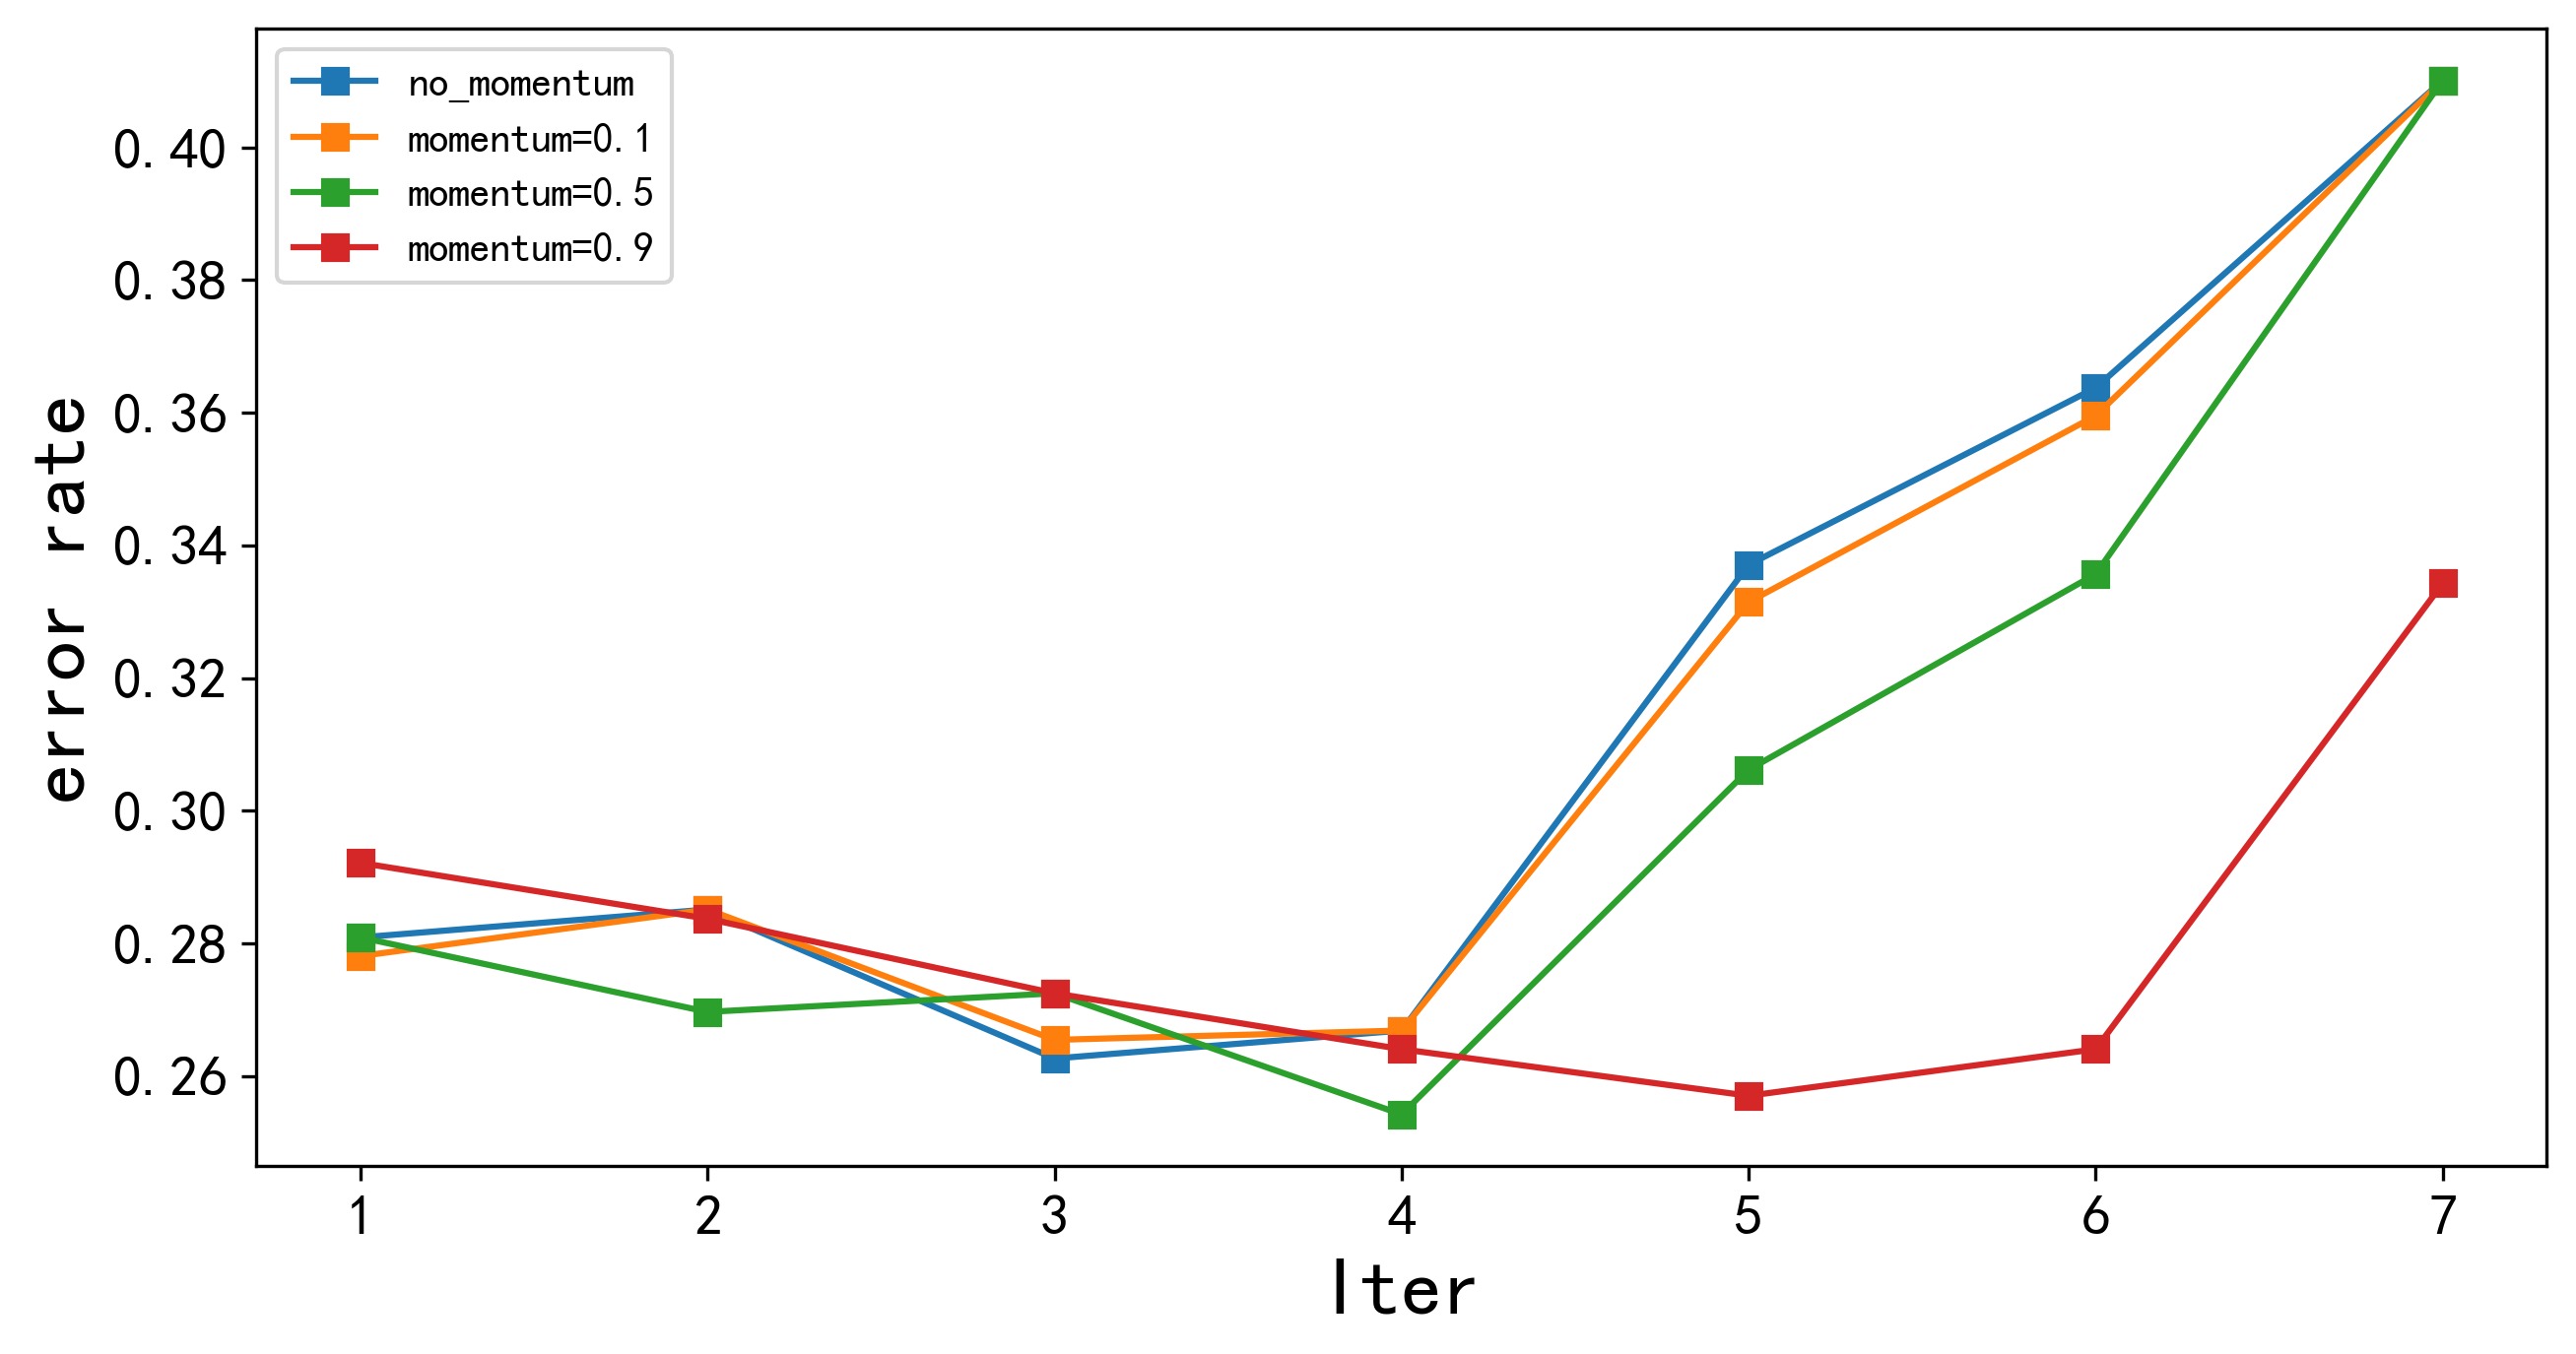

In [18]:
no_momentum = exec_result.query('use_momentum==False')
momentum_01 = exec_result.query('momentum==0.1')
momentum_05 = exec_result.query('momentum==0.5')
momentum_09 = exec_result.query('momentum==0.9')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']
plt.plot(range(1,len(no_momentum)+1), no_momentum['best_errors_val'].values.tolist(), marker='s', label='no_momentum')
plt.plot(range(1,len(no_momentum)+1), momentum_01['best_errors_val'].values.tolist(), marker='s', label='momentum=0.1')
plt.plot(range(1,len(no_momentum)+1), momentum_05['best_errors_val'].values.tolist(), marker='s', label='momentum=0.5')
plt.plot(range(1,len(no_momentum)+1), momentum_09['best_errors_val'].values.tolist(), marker='s', label='momentum=0.9')
plt.xlabel('Iter', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks(range(1,len(no_momentum)+1), fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

#### 学习率对结果的影响

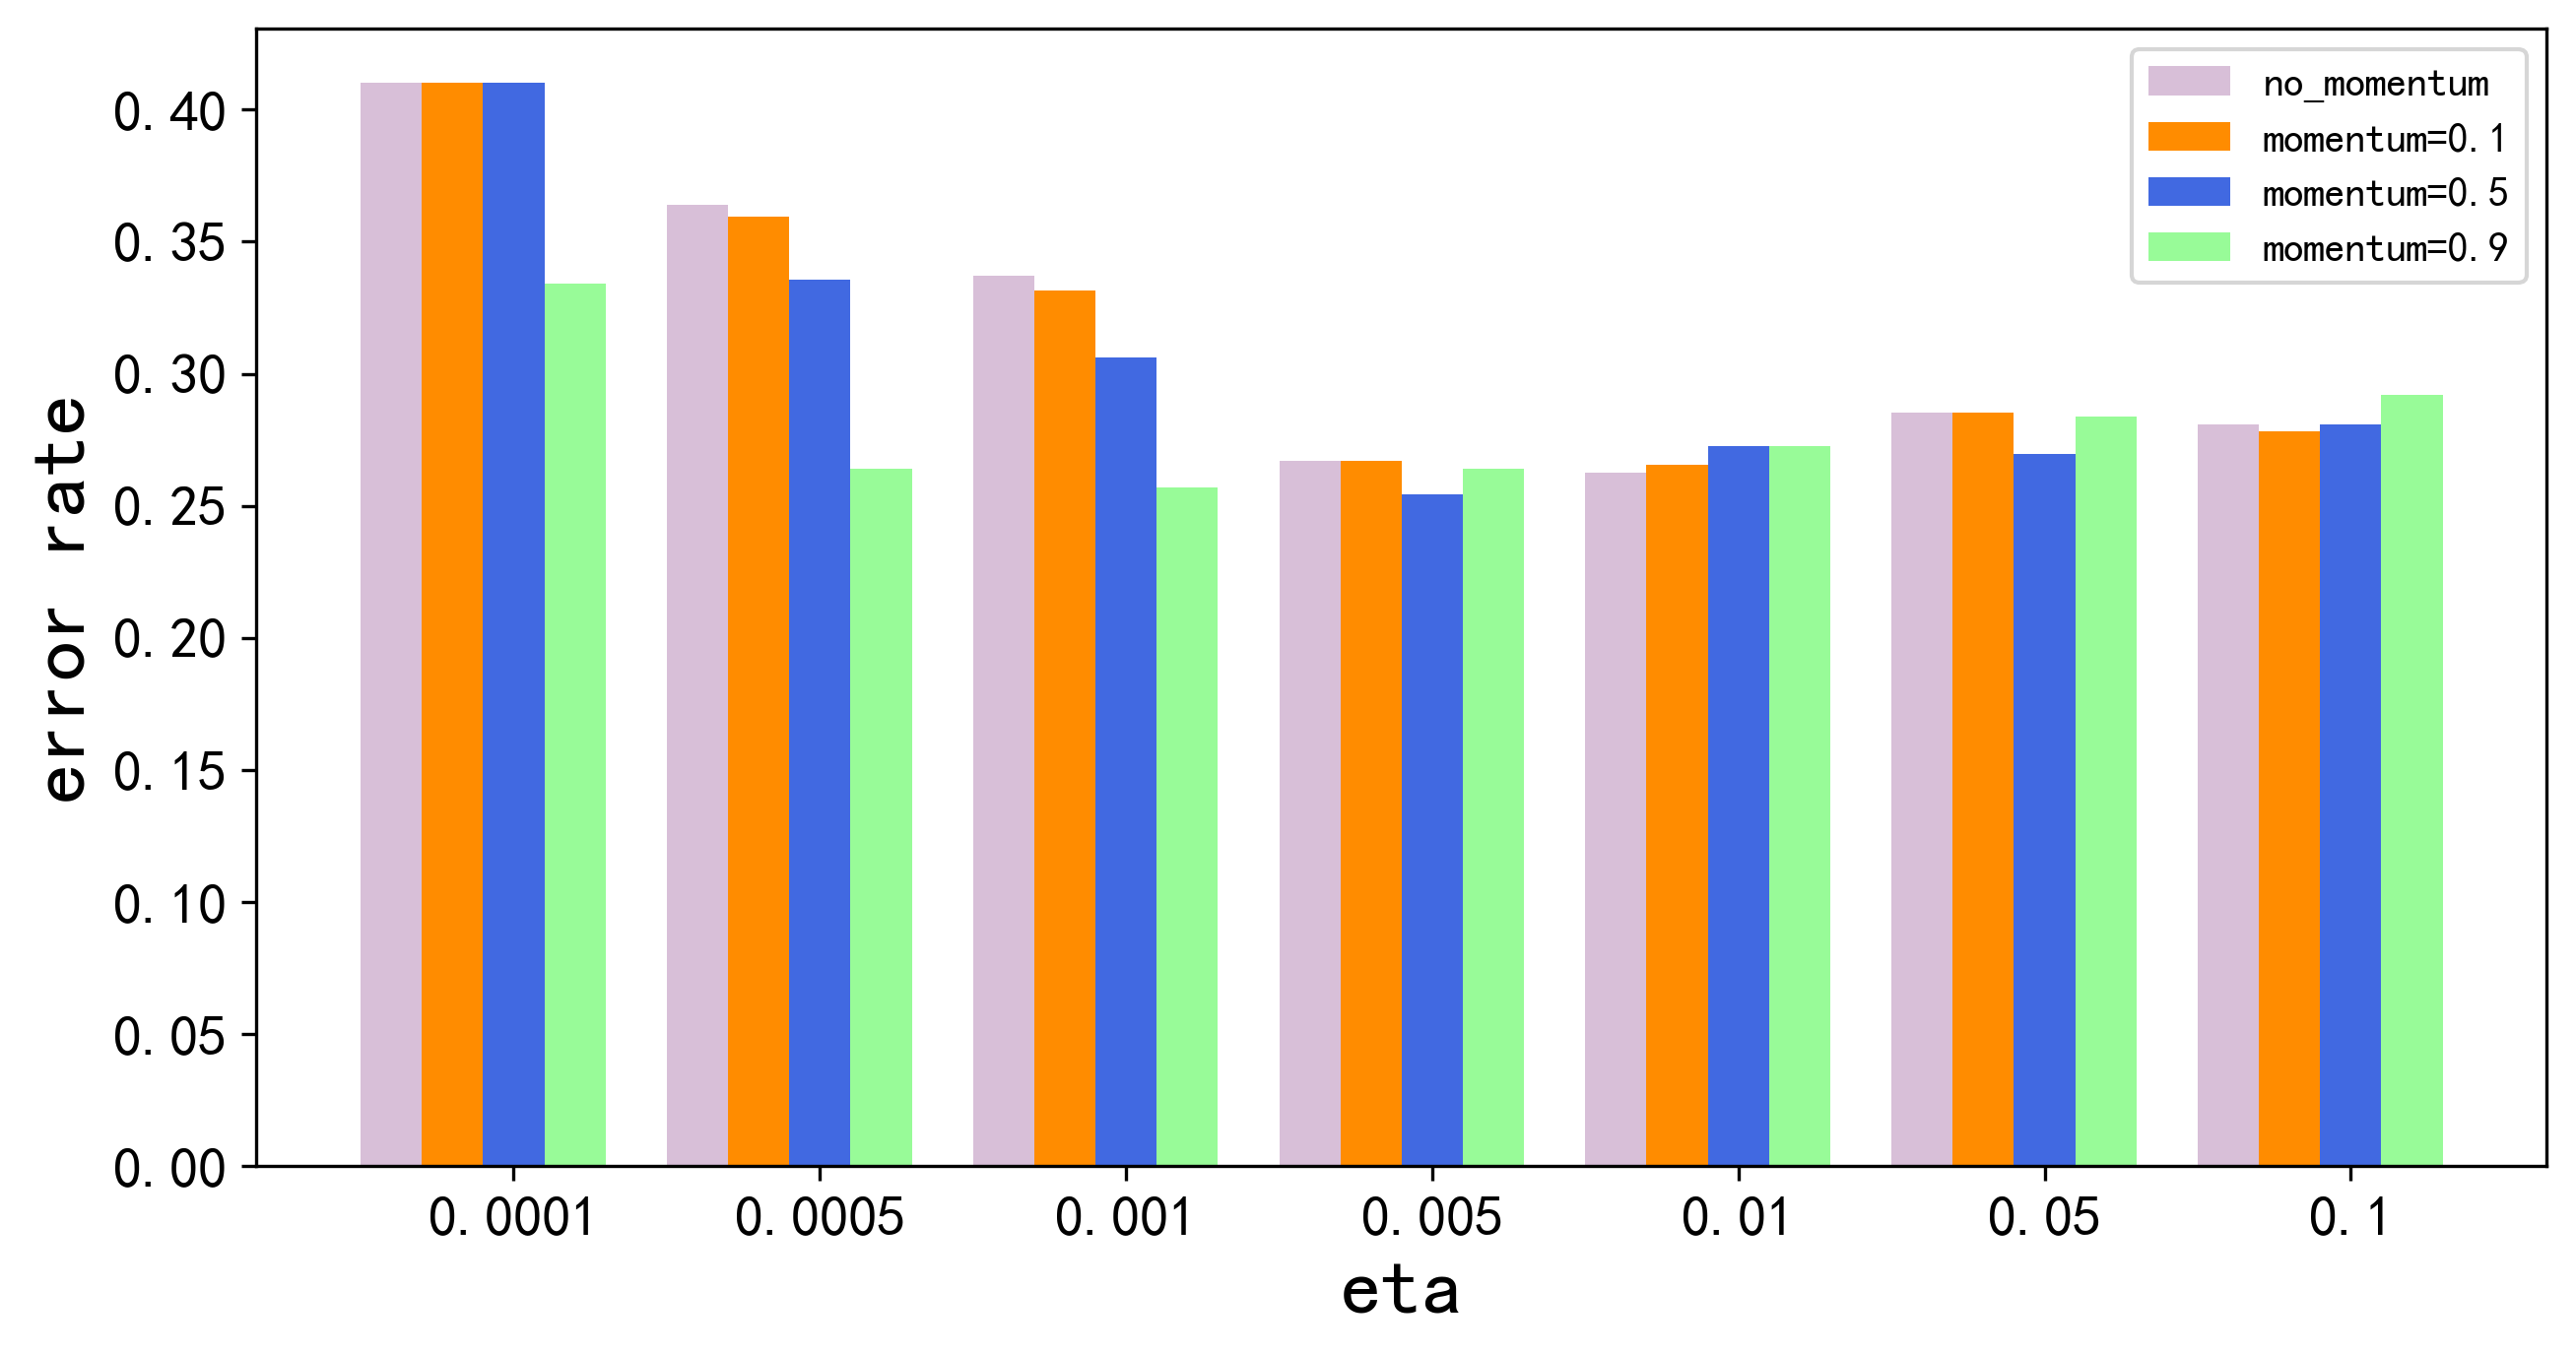

In [19]:
no_momentum = exec_result.query('use_momentum==False')
momentum_01 = exec_result.query('momentum==0.1')
momentum_05 = exec_result.query('momentum==0.5')
momentum_09 = exec_result.query('momentum==0.9')
plt.figure(figsize=(10,5), dpi=300)
plt.rcParams['font.sans-serif']=['SimHei']

plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.6, no_momentum['best_errors_val'].values.tolist()[::-1], width=0.2, color='thistle', label='no_momentum')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+0.8, momentum_01['best_errors_val'].values.tolist()[::-1], width=0.2, color='darkorange', label='momentum=0.1')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.0, momentum_05['best_errors_val'].values.tolist()[::-1], width=0.2, color='royalblue', label='momentum=0.5')
plt.bar(np.array(range(0,len(no_momentum['eta'])))+1.2, momentum_09['best_errors_val'].values.tolist()[::-1], width=0.2, color='palegreen', label='momentum=0.9')

plt.xlabel('eta', fontsize=20, fontweight='bold')
plt.ylabel('error rate', fontsize=20, fontweight='bold')
plt.xticks([1,2,3,4,5,6,7],[0.0001, 0.0005, 0.001, 0.005, 0.01, 0.05, 0.1], fontsize=14)
plt.yticks(fontsize=14)
plt.legend()
plt.show()

In [20]:
no_momentum['best_errors_val'].values.tolist()[::-1]

[0.4101123595505618,
 0.3637640449438202,
 0.33707865168539325,
 0.26685393258426965,
 0.26264044943820225,
 0.2851123595505618,
 0.2808988764044944]

### 最佳模型

In [21]:
# 取最佳模型
best_index = exec_result['best_errors_val'].idxmin()  
best_result = exec_result.iloc[best_index]
best_result

model                                                            bow
epochs                                                            20
eta                                                            0.005
use_momentum                                                    True
momentum                                                         0.5
best_epoch                                                         9
best_errors_val                                             0.254213
best_weights       {'die': -0.12499999999999997, 'another': -0.21...
losses_train       [0.8931794167005597, 0.6963540839226903, 0.589...
losses_val         [0.801966650497756, 0.7513298309589374, 0.7222...
errors_train       [0.3058161350844278, 0.24046278924327705, 0.17...
errors_val         [0.3707865168539326, 0.3398876404494382, 0.314...
Name: 13, dtype: object

### loss和error rate可视化

In [22]:
def visualization(losses_train, losses_val, errors_train, errors_val):
    plt.figure(figsize=(14,5), dpi=150)
    plt.rcParams['font.sans-serif']=['SimHei']
    plt.subplot(121)
    plt.plot(range(1,len(losses_train)+1), losses_train, marker='s', label='train')
    plt.plot(range(1,len(losses_val)+1), losses_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=18, fontweight='bold')
    plt.ylabel('loss', fontsize=18, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.subplot(122)
    plt.plot(range(1,len(errors_train)+1), errors_train, marker='s', label='train')
    plt.plot(range(1,len(errors_val)+1), errors_val, marker='s', label='val')
    plt.xlabel('epoch', fontsize=20, fontweight='bold')
    plt.ylabel('error rate', fontsize=20, fontweight='bold')
    plt.xticks(range(2,len(errors_train)+1,2), fontsize=14)
    plt.yticks(fontsize=14)
    plt.legend()
    plt.show()

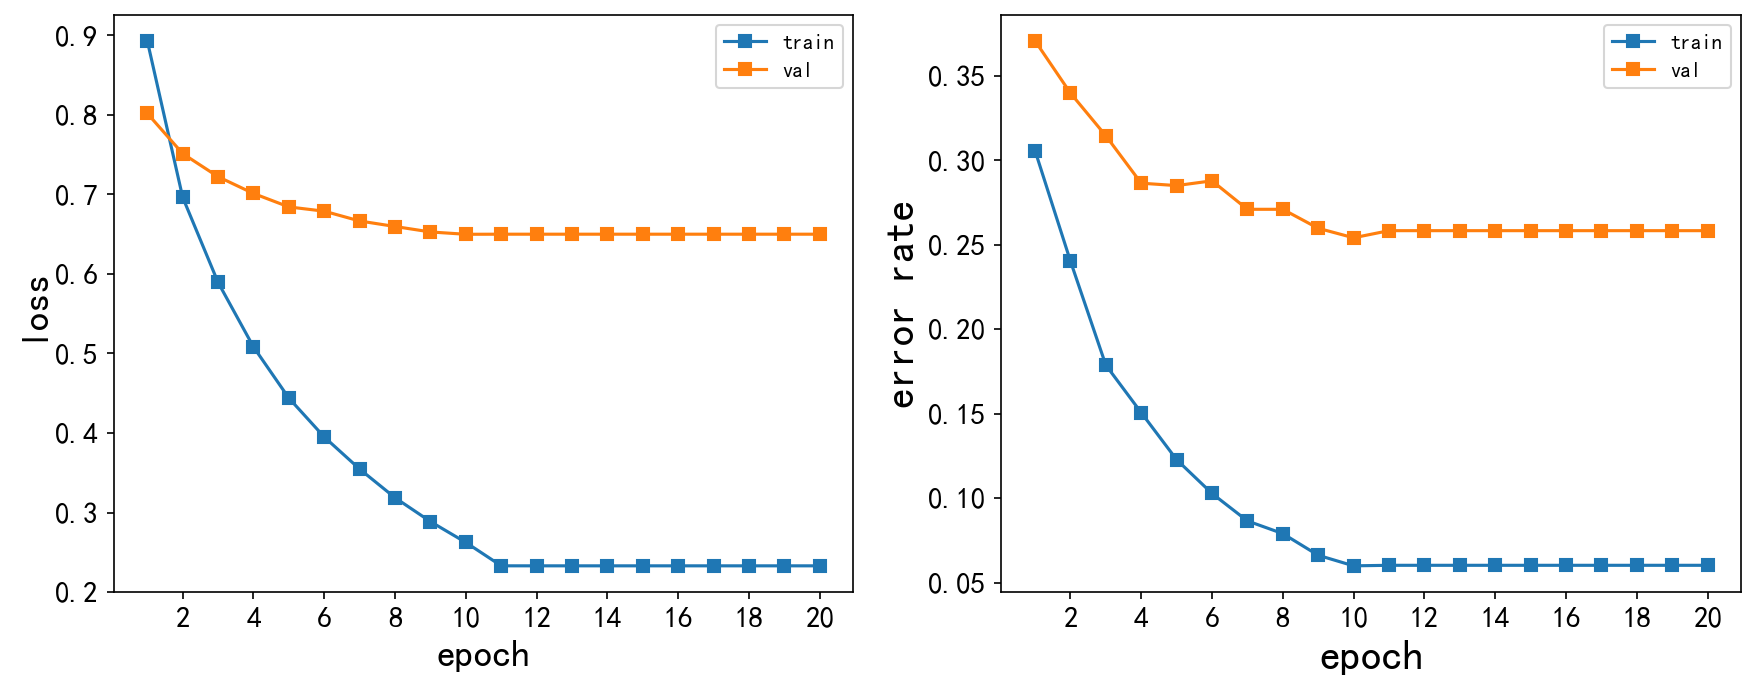

In [23]:
visualization(best_result.losses_train, 
              best_result.losses_val,
              best_result.errors_train,
              best_result.errors_val)

### 测试模型

In [1]:
# 取验证集上最好结果的权重来测试
trainError = evaluatePredictor(trainExamples, 
                               lambda x : (1 if dotProduct(featureExtractor(x), best_result.best_weights) >= 0 else -1))
testError = evaluatePredictor(testExamples, 
                              lambda x : (1 if dotProduct(featureExtractor(x), best_result.best_weights) >= 0 else -1))
print ("train error = %4f, validate error = %4f, test error = %4f" % (trainError, best_result.best_errors_val, testError)) 


train error = 0.060350, validate error = 0.254213, test error = 0.277361


## 权重可解释性

In [25]:
positive= sorted(weights.items(), key=lambda d:d[1], reverse = True)
print('positive:')
for p in positive[:50]:
    print(p)
negative= sorted(weights.items(), key=lambda d:d[1], reverse = False)
print('\n','negative:')
for n in negative[:50]:
    print(n)

positive:
('of', 0.10703773731080005)
('and', 0.10702557629736621)
('film', 0.09000178227497972)
('an', 0.06700037842987822)
('with', 0.054950024366750394)
(',', 0.05398957867111732)
('a', 0.050995833712931704)
('funny', 0.034999999999976696)
('performances', 0.03299999999999992)
('world', 0.026999999999999892)
('best', 0.025012499999999903)
('from', 0.024006249999813645)
('moving', 0.022999999999999916)
('make', 0.0229999996185302)
('works', 0.021999999999999922)
("it's", 0.021989453124999912)
('work', 0.02099999999999993)
('entertaining', 0.020949243544042036)
('life', 0.019999999999999934)
('most', 0.01899687499999994)
('heart', 0.016999999999999953)
('compelling', 0.016999999999999953)
('their', 0.01602499999999996)
('tale', 0.01600000019110735)
('love', 0.016000000000372487)
('us', 0.016000000000093093)
('enjoyable', 0.01599999999999996)
('human', 0.01599999999999996)
('its', 0.01595002442598116)
('does', 0.015000000000005785)
('though', 0.014999999999999965)
('our', 0.01499999999

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


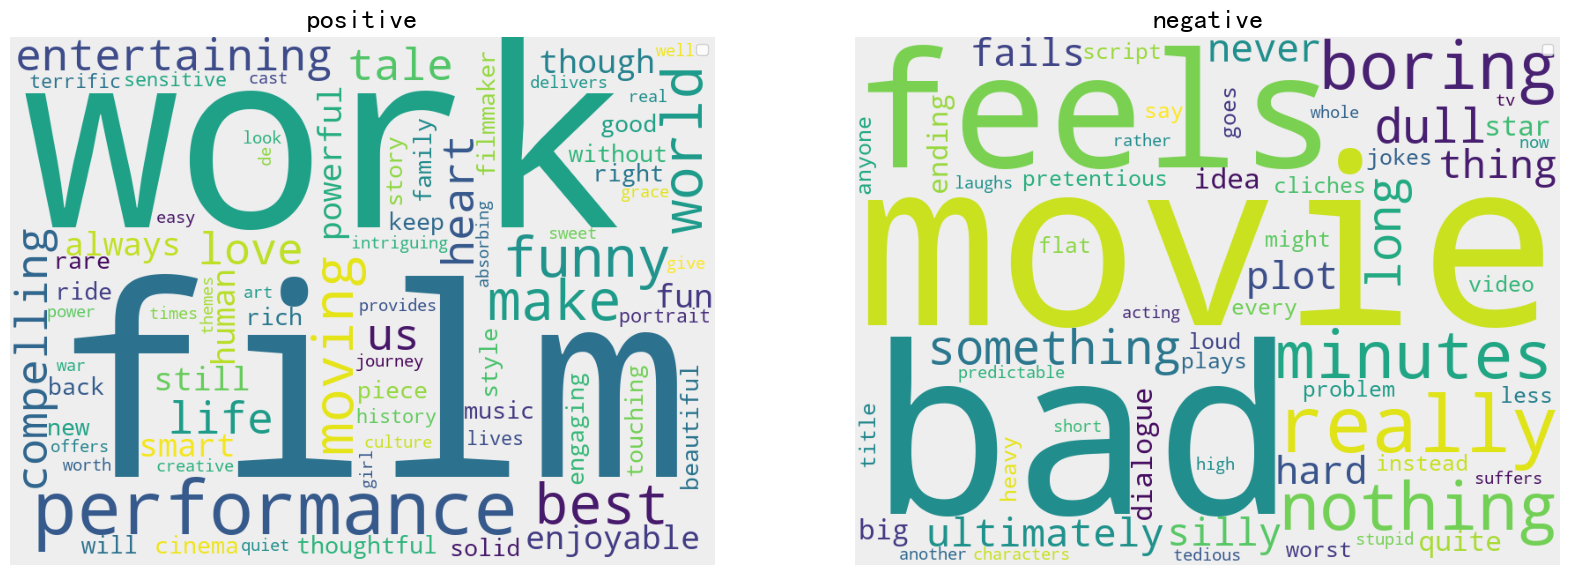

In [26]:
plt.figure(figsize=(20,10), dpi=100)
plt.rcParams['font.sans-serif']=['SimHei']
plt.subplot(121)
wc_poc = WordCloud(width=800, height=600, background_color='#eeeeee')
wc_poc.generate(' '.join([p[0] for p in positive[:100]]))
wc_poc.to_image()

plt.imshow(wc_poc.to_image())
plt.axis('off')
plt.title('positive', fontsize=20, fontweight='bold') 
plt.legend()

plt.subplot(122)
wc_neg = WordCloud(width=800, height=600, background_color='#eeeeee')
wc_neg.generate(' '.join([n[0] for n in negative[:100]]))
wc_neg.to_image()
plt.imshow(wc_neg.to_image())
plt.axis('off')
plt.title('negative', fontsize=20, fontweight='bold') 
plt.legend()
plt.show()

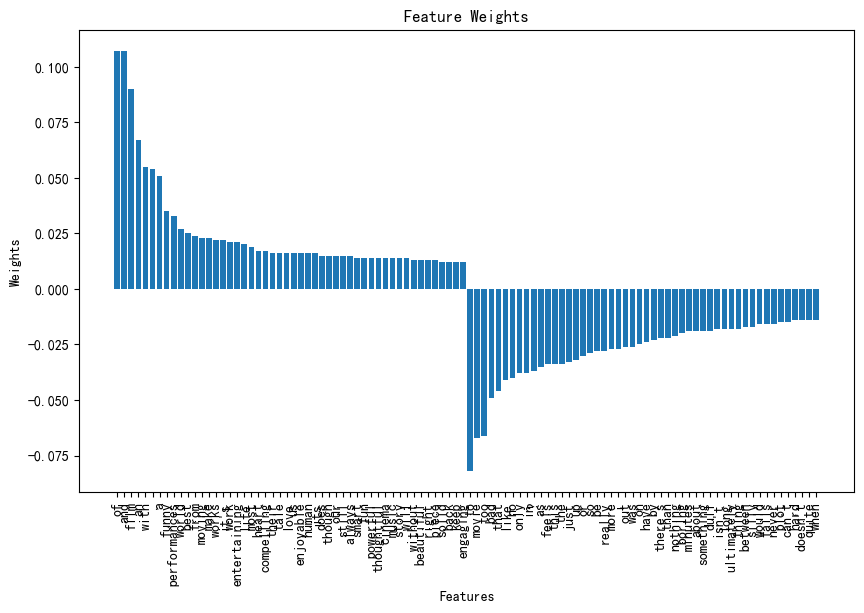

In [27]:
features = []
weights_score = []
for feature, weight in positive[:50]:
    features.append(feature)
    weights_score.append(weight)
for feature, weight in negative[:50]:
    features.append(feature)
    weights_score.append(weight)

# 绘制条形图
plt.figure(figsize=(10,6))
plt.rcParams['axes.unicode_minus'] = False 
plt.bar(features, weights_score)
plt.title('Feature Weights')
plt.xlabel('Features')
plt.ylabel('Weights')
plt.xticks(rotation=90)
plt.show()

训练出来的权重在文本情感分析中可以用于解释不同的特征在分类中的相对重要性。例如，某个词语的权重值越大，表示该词语对分类结果的影响越大，即该词语对文本情感判断的重要性更高。

同时，这些权重也可以用于解释分类器所依赖的特征。例如，在二分类任务中，对于一个给定的权重向量，可以通过查看权重最大的特征来了解模型是如何进行分类的，即模型关注哪些方面的特征来作出判断。

In [28]:

examples = []
for line in open('./data/data_rt.train', encoding = "ISO-8859-1"):
    # Format of each line: <output label (+1 or -1)> <input sentence>
    y, x = line.split(' ', 1)

    examples.append((pre_data(x), int(y)))

for e in examples[254:272]:
    print(('+1' if e[1] ==1 else '-1')+ ' '+ e[0])
    # print(e[0])


-1 brady achieves the remarkable feat of squandering a topnotch foursome of actors . . . by shoving them into every cliched white-trash situation imaginable .
+1 this is one of the rarest kinds of films : a family-oriented non-disney film that is actually funny without hitting below the belt .
+1 rabbit-proof fence will probably make you angry . but it will just as likely make you weep , and it will do so in a way that doesn't make you feel like a sucker .
+1 o Ultimo suspeito ganha forca ao tambem funcionar em uma esfera adicional : a do drama familiar .
-1 an awkwardly garish showcase that diverges from anything remotely probing or penetrating .
+1 [taymor] utilizes the idea of making kahlo's art a living , breathing part of the movie , often catapulting the artist into her own work . this isn't a new idea . it's been done before but never so vividly or with so much passion .
-1 the script boasts some tart tv-insider humor , but the film has not a trace of humanity or empathy .
+1 en